# RQ1第二步：Spatial mean-flow baseline

这份notebook在已经固定的5,117个forecast cases上实现**空间平均流场基线**。它只使用training drifters的历史观测，在不同空间网格中估计平均东西向速度和南北向速度；预测时，drifter每前进一步都会重新查询当前位置的平均流速。

最终评价仍只报告相同的757个test cases，并使用与velocity-persistence完全相同的Haversine separation error、RMSE和integrated trajectory error（ITE）。

## 1. 方法

在空间网格 $g$ 中，用training observations估计：

$$\bar v_e(g)=\frac{1}{N_g}\sum_{i\in g}v_{e,i},\qquad
\bar v_n(g)=\frac{1}{N_g}\sum_{i\in g}v_{n,i}.$$

预测从forecast origin开始。每一个小时先查询当前位置所在网格的 $(\bar v_e,\bar v_n)$，再在球面上向前积分一小时。下一小时会根据新的预测位置重新查询流速，因此轨迹可以随着空间位置改变而转弯。

为避免稀疏或空网格导致无法预测，本notebook采用完全基于training data的三级规则：

1. 优先使用至少24条training observations的 $0.25^\circ\times0.25^\circ$ 细网格；
2. 若细网格不足，则使用至少24条training observations的 $1^\circ\times1^\circ$ 粗网格；
3. 若仍然不可用，则使用整个training region的平均速度。

Calibration和test observations不会参与流场估计。

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython import get_ipython
from IPython.display import display

ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic('matplotlib', 'inline')

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'processed').exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('找不到data/processed；请从项目目录或notebooks子目录打开。')

PROCESSED = PROJECT_ROOT / 'data' / 'processed'
OUTPUT_DIR = PROJECT_ROOT / 'output' / 'rq1' / 'zh'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EARTH_RADIUS_M = 6_371_000.0
HORIZON_HOURS = 72
FINE_GRID_DEG = 0.25
COARSE_GRID_DEG = 1.0
MIN_CELL_OBSERVATIONS = 24
GRID_ORIGIN_LON = 125.0
GRID_ORIGIN_LAT = 25.0

plt.rcParams['font.sans-serif'] = ['PingFang SC', 'Arial Unicode MS', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
print('项目目录：', PROJECT_ROOT.resolve())
print('结果目录：', OUTPUT_DIR.resolve())

项目目录： /Users/roger/Documents/data3001-project-main
结果目录： /Users/roger/Documents/data3001-project-main/output/rq1/zh


## 2. 读取固定cases、drifter划分与观测

`drifter_splits.csv`固定了每条drifter属于training、calibration还是test。空间流场只使用training IDs的观测；`forecast_origins.parquet`仍决定5,117个case从哪里开始。

In [2]:
origins = pd.read_parquet(PROCESSED / 'forecast_origins.parquet')
splits = pd.read_csv(PROCESSED / 'drifter_splits.csv')
observations = pd.read_parquet(
    PROCESSED / 'region_A_observations.parquet',
    columns=['ID', 'segment_id', 'segment_step', 'time', 'latitude', 'longitude', 've', 'vn'],
)

training_ids = set(splits.loc[splits['partition'].eq('training'), 'ID'])
flow_training = observations[observations['ID'].isin(training_ids)].copy()
flow_training = flow_training.dropna(subset=['latitude', 'longitude', 've', 'vn'])

dataset_summary = pd.DataFrame({
    '项目': [
        '全部forecast cases', 'Training cases', 'Calibration cases', 'Test cases',
        'Training drifters', '用于估计流场的training observations',
    ],
    '数量': [
        len(origins), origins['partition'].eq('training').sum(),
        origins['partition'].eq('calibration').sum(), origins['partition'].eq('test').sum(),
        len(training_ids), len(flow_training),
    ],
})
display(dataset_summary)

assert len(origins) == 5117
assert origins['partition'].eq('test').sum() == 757
assert set(flow_training['ID']).issubset(training_ids)
assert not set(splits.loc[splits['partition'].ne('training'), 'ID']).intersection(flow_training['ID'])

,项目,数量
0,全部forecast cases,5117
1,Training cases,3591
2,Calibration cases,769
3,Test cases,757
4,Training drifters,364
5,用于估计流场的training observations,392533


## 3. 仅用training observations构造多尺度平均流场

细网格保留局部空间差异；粗网格和区域平均只在细网格数据不足时回退使用。`n_observations`表示一个网格中用于估计均值的training observations数量。

In [3]:
def add_grid_indices(frame, grid_deg):
    result = frame.copy()
    result['grid_x'] = np.floor((result['longitude'] - GRID_ORIGIN_LON) / grid_deg).astype(int)
    result['grid_y'] = np.floor((result['latitude'] - GRID_ORIGIN_LAT) / grid_deg).astype(int)
    return result


def build_flow_grid(frame, grid_deg, minimum_count):
    indexed = add_grid_indices(frame, grid_deg)
    grid = (
        indexed.groupby(['grid_x', 'grid_y'])
        .agg(
            mean_ve=('ve', 'mean'),
            mean_vn=('vn', 'mean'),
            n_observations=('ve', 'size'),
            n_drifters=('ID', 'nunique'),
        )
        .reset_index()
    )
    grid = grid[grid['n_observations'].ge(minimum_count)].copy()
    grid['center_longitude'] = GRID_ORIGIN_LON + (grid['grid_x'] + 0.5) * grid_deg
    grid['center_latitude'] = GRID_ORIGIN_LAT + (grid['grid_y'] + 0.5) * grid_deg
    grid['mean_speed'] = np.hypot(grid['mean_ve'], grid['mean_vn'])
    return grid


fine_flow = build_flow_grid(flow_training, FINE_GRID_DEG, MIN_CELL_OBSERVATIONS)
coarse_flow = build_flow_grid(flow_training, COARSE_GRID_DEG, MIN_CELL_OBSERVATIONS)
regional_mean_ve = float(flow_training['ve'].mean())
regional_mean_vn = float(flow_training['vn'].mean())

fine_lookup = {
    (int(r.grid_x), int(r.grid_y)): (float(r.mean_ve), float(r.mean_vn))
    for r in fine_flow.itertuples()
}
coarse_lookup = {
    (int(r.grid_x), int(r.grid_y)): (float(r.mean_ve), float(r.mean_vn))
    for r in coarse_flow.itertuples()
}

flow_summary = pd.DataFrame({
    '流场层级': ['0.25°细网格', '1°粗网格', '区域平均'],
    '可用单元数': [len(fine_flow), len(coarse_flow), 1],
    '最低观测数要求': [MIN_CELL_OBSERVATIONS, MIN_CELL_OBSERVATIONS, len(flow_training)],
})
display(flow_summary)
print(f'区域平均速度：ve={regional_mean_ve:.4f} m/s, vn={regional_mean_vn:.4f} m/s')
assert len(fine_lookup) > 0 and len(coarse_lookup) > 0

,流场层级,可用单元数,最低观测数要求
0,0.25°细网格,1325,24
1,1°粗网格,95,24
2,区域平均,1,392533


区域平均速度：ve=0.1145 m/s, vn=0.1085 m/s


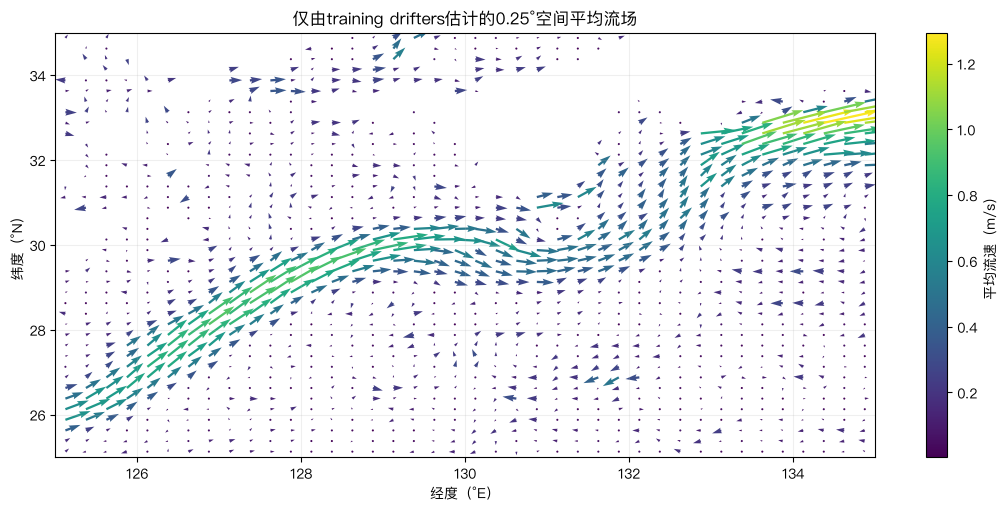

In [4]:
fig, ax = plt.subplots(figsize=(11, 5.2))
q = ax.quiver(
    fine_flow['center_longitude'], fine_flow['center_latitude'],
    fine_flow['mean_ve'], fine_flow['mean_vn'], fine_flow['mean_speed'],
    cmap='viridis', angles='xy', scale_units='xy', scale=1.8, width=0.0028,
)
fig.colorbar(q, ax=ax, label='平均流速（m/s）')
ax.set(
    xlabel='经度（°E）', ylabel='纬度（°N）',
    title='仅由training drifters估计的0.25°空间平均流场',
)
ax.set_xlim(125, 135)
ax.set_ylim(25, 35)
ax.grid(alpha=0.2)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'spatial_mean_flow_field.png', dpi=200, bbox_inches='tight')
plt.show()

## 4. 递归预测未来72小时位置

与velocity persistence不同，mean-flow在每一个预测小时都会使用**当前预测位置**重新查询平均流速。下面的循环同时预测全部5,117个cases，并记录每一步使用的是细网格、粗网格还是区域平均回退。

In [5]:
def grid_key(lon, lat, grid_deg):
    return (
        int(np.floor((lon - GRID_ORIGIN_LON) / grid_deg)),
        int(np.floor((lat - GRID_ORIGIN_LAT) / grid_deg)),
    )


def lookup_mean_flow(latitudes, longitudes):
    ve_out = np.empty(len(latitudes), dtype=float)
    vn_out = np.empty(len(latitudes), dtype=float)
    sources = np.empty(len(latitudes), dtype=object)

    for i, (lat, lon) in enumerate(zip(latitudes, longitudes)):
        fine = fine_lookup.get(grid_key(lon, lat, FINE_GRID_DEG))
        if fine is not None:
            ve_out[i], vn_out[i] = fine
            sources[i] = 'fine_0.25deg'
            continue

        coarse = coarse_lookup.get(grid_key(lon, lat, COARSE_GRID_DEG))
        if coarse is not None:
            ve_out[i], vn_out[i] = coarse
            sources[i] = 'coarse_1deg'
            continue

        ve_out[i], vn_out[i] = regional_mean_ve, regional_mean_vn
        sources[i] = 'regional_mean'

    return ve_out, vn_out, sources


state = origins[[
    'forecast_case_id', 'ID', 'segment_id', 'partition', 'target_start_step',
    'origin_time', 'origin_latitude', 'origin_longitude',
]].copy()
state['pred_latitude'] = state['origin_latitude'].astype(float)
state['pred_longitude'] = state['origin_longitude'].astype(float)

prediction_steps = []
for lead_time in range(1, HORIZON_HOURS + 1):
    flow_ve, flow_vn, flow_source = lookup_mean_flow(
        state['pred_latitude'].to_numpy(),
        state['pred_longitude'].to_numpy(),
    )

    lat_rad = np.deg2rad(state['pred_latitude'].to_numpy())
    lon_rad = np.deg2rad(state['pred_longitude'].to_numpy())
    pred_lat_rad = lat_rad + flow_vn * 3600.0 / EARTH_RADIUS_M
    cos_lat = np.cos(lat_rad)
    if np.any(np.abs(cos_lat) < 1e-8):
        raise ValueError('出现过于接近极点的位置，经度积分不稳定。')
    pred_lon_rad = lon_rad + flow_ve * 3600.0 / (EARTH_RADIUS_M * cos_lat)

    state['pred_latitude'] = np.rad2deg(pred_lat_rad)
    state['pred_longitude'] = (np.rad2deg(pred_lon_rad) + 180.0) % 360.0 - 180.0

    step = state[[
        'forecast_case_id', 'ID', 'segment_id', 'partition', 'target_start_step',
        'origin_time', 'origin_latitude', 'origin_longitude',
        'pred_latitude', 'pred_longitude',
    ]].copy()
    step['lead_time_hours'] = lead_time
    step['flow_ve'] = flow_ve
    step['flow_vn'] = flow_vn
    step['flow_source'] = flow_source
    step['segment_step'] = step['target_start_step'] + lead_time - 1
    prediction_steps.append(step)

evaluation = pd.concat(prediction_steps, ignore_index=True)
display(evaluation[[
    'forecast_case_id', 'lead_time_hours', 'flow_source',
    'flow_ve', 'flow_vn', 'pred_latitude', 'pred_longitude',
]].head())

assert len(evaluation) == len(origins) * HORIZON_HOURS
assert evaluation.groupby('forecast_case_id').size().eq(HORIZON_HOURS).all()

,forecast_case_id,lead_time_hours,flow_source,flow_ve,flow_vn,pred_latitude,pred_longitude
0,1,1,fine_0.25deg,0.076619,0.121737,26.848581,125.209620
1,2,1,fine_0.25deg,0.067600,0.084486,27.521975,125.230848
2,3,1,fine_0.25deg,0.101666,0.083500,27.782063,125.423760
3,4,1,fine_0.25deg,0.102652,0.068392,27.781884,125.230986
4,5,1,fine_0.25deg,0.076139,0.124736,27.165818,125.405281


## 5. 合并真实位置并计算Haversine separation error

合并键仍是`ID + segment_id + segment_step`。Haversine函数与velocity-persistence notebook完全相同，保证两个baselines可以公平比较。

In [6]:
truth = observations[['ID', 'segment_id', 'segment_step', 'time', 'latitude', 'longitude']].rename(columns={
    'time': 'valid_time',
    'latitude': 'true_latitude',
    'longitude': 'true_longitude',
})
evaluation = evaluation.merge(
    truth,
    on=['ID', 'segment_id', 'segment_step'],
    how='left',
    validate='many_to_one',
)

def haversine_km(lat1, lon1, lat2, lon2):
    lat1 = np.deg2rad(np.asarray(lat1, dtype=float))
    lon1 = np.deg2rad(np.asarray(lon1, dtype=float))
    lat2 = np.deg2rad(np.asarray(lat2, dtype=float))
    lon2 = np.deg2rad(np.asarray(lon2, dtype=float))
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * (EARTH_RADIUS_M / 1000.0) * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

evaluation['separation_error_km'] = haversine_km(
    evaluation['pred_latitude'], evaluation['pred_longitude'],
    evaluation['true_latitude'], evaluation['true_longitude'],
)

checks = pd.Series({
    '所有真实位置均成功匹配': evaluation[['true_latitude', 'true_longitude']].notna().all().all(),
    '所有预测误差均为有限数值': np.isfinite(evaluation['separation_error_km']).all(),
    '每个case恰好有72个lead times': evaluation.groupby('forecast_case_id').size().eq(72).all(),
}, name='是否通过')
display(checks.to_frame())
assert checks.all()

,是否通过
所有真实位置均成功匹配,True
所有预测误差均为有限数值,True
每个case恰好有72个lead times,True


## 6. 测试集结果：误差怎样随lead time增长？

下面只使用相同的757个test cases。实线是median separation error，阴影是25%到75%分位区间。流场来源表用于检查稀疏网格回退规则实际被使用了多少。

In [7]:
test_eval = evaluation[evaluation['partition'].eq('test')].copy()
lead_metrics = (
    test_eval.groupby('lead_time_hours')['separation_error_km']
    .agg(
        n='size',
        median_error_km='median',
        mean_error_km='mean',
        q25_error_km=lambda x: x.quantile(0.25),
        q75_error_km=lambda x: x.quantile(0.75),
        rmse_km=lambda x: np.sqrt(np.mean(np.square(x))),
    )
    .reset_index()
)

fallback_usage = (
    test_eval['flow_source'].value_counts()
    .rename_axis('流场来源').reset_index(name='预测步数')
)
fallback_usage['占测试集预测步比例'] = fallback_usage['预测步数'] / len(test_eval)

assert test_eval['forecast_case_id'].nunique() == 757
assert lead_metrics['n'].eq(757).all()
display(lead_metrics[lead_metrics['lead_time_hours'].isin([1, 6, 12, 24, 48, 72])].round(2))
display(fallback_usage.style.format({'占测试集预测步比例': '{:.1%}'}))

,lead_time_hours,n,median_error_km,mean_error_km,q25_error_km,q75_error_km,rmse_km
0,1,757,1.13,1.29,0.70,1.66,1.53
5,6,757,6.22,7.15,3.84,9.41,8.42
11,12,757,11.48,13.26,6.91,17.69,15.82
23,24,757,21.69,24.87,13.04,33.36,29.87
47,48,757,39.96,47.12,22.48,63.38,57.27
71,72,757,56.42,66.76,32.84,88.69,80.98


,流场来源,预测步数,占测试集预测步比例
0,fine_0.25deg,53024,97.3%
1,coarse_1deg,1110,2.0%
2,regional_mean,370,0.7%


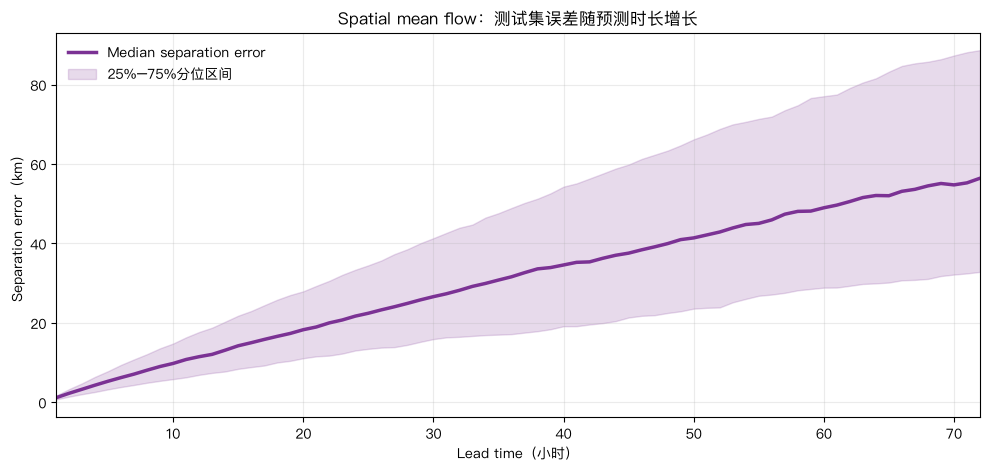

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.8))
x = lead_metrics['lead_time_hours'].to_numpy()
median = lead_metrics['median_error_km'].to_numpy()
q25 = lead_metrics['q25_error_km'].to_numpy()
q75 = lead_metrics['q75_error_km'].to_numpy()
ax.plot(x, median, color='#7b3294', linewidth=2.5, label='Median separation error')
ax.fill_between(x, q25, q75, color='#7b3294', alpha=0.18, label='25%–75%分位区间')
ax.set(
    xlabel='Lead time（小时）', ylabel='Separation error（km）',
    title='Spatial mean flow：测试集误差随预测时长增长',
)
ax.set_xlim(1, 72)
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'spatial_mean_flow_error_curve.png', dpi=200, bbox_inches='tight')
plt.show()

## 7. Case-level integrated trajectory error与汇总

对每个test case，将0到72小时的separation error进行梯形积分得到ITE（km·h）。这衡量整条预测轨迹的累计偏差，而不只看72小时终点。

In [9]:
def case_metrics(group):
    ordered = group.sort_values('lead_time_hours')
    errors = ordered['separation_error_km'].to_numpy()
    hours = ordered['lead_time_hours'].to_numpy()
    ite = np.trapezoid(np.r_[0.0, errors], x=np.r_[0, hours])
    return pd.Series({
        'integrated_trajectory_error_km_h': ite,
        'final_72h_error_km': errors[-1],
        'mean_trajectory_error_km': errors.mean(),
    })

test_case_metrics = test_eval.groupby('forecast_case_id', sort=False).apply(
    case_metrics, include_groups=False
).reset_index()

def metric_at(hour, column):
    return float(lead_metrics.loc[lead_metrics['lead_time_hours'].eq(hour), column].iloc[0])

summary = pd.DataFrame({
    '指标': [
        'Test cases', '24h median error (km)', '48h median error (km)',
        '72h median error (km)', '72h RMSE (km)', 'Median ITE (km·h)',
    ],
    '结果': [
        test_eval['forecast_case_id'].nunique(),
        metric_at(24, 'median_error_km'), metric_at(48, 'median_error_km'),
        metric_at(72, 'median_error_km'), metric_at(72, 'rmse_km'),
        test_case_metrics['integrated_trajectory_error_km_h'].median(),
    ],
})
display(summary.round(2))

,指标,结果
0,Test cases,757.00
1,24h median error (km),21.69
2,48h median error (km),39.96
3,72h median error (km),56.42
4,72h RMSE (km),80.98
5,Median ITE (km·h),2201.71


## 8. 与velocity-persistence baseline公平比较

如果第一份notebook的结果文件存在，这里会在相同757个test cases、相同lead times和相同误差函数下比较两条median error曲线。数值更低的baseline表现更好。

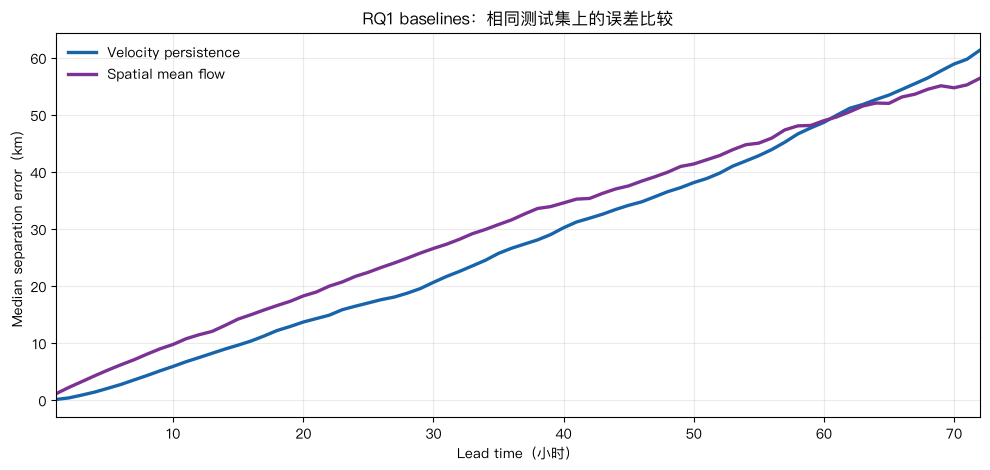

,lead_time_hours,median_error_km_mean_flow,rmse_km_mean_flow,median_error_km_persistence,rmse_km_persistence
23,24,21.69,29.87,16.47,24.07
47,48,39.96,57.27,36.54,55.17
71,72,56.42,80.98,61.35,90.10


In [10]:
persistence_path = OUTPUT_DIR / 'velocity_persistence_lead_metrics.csv'
if persistence_path.exists():
    persistence_metrics = pd.read_csv(persistence_path)
    comparison = lead_metrics[['lead_time_hours', 'median_error_km', 'rmse_km']].merge(
        persistence_metrics[['lead_time_hours', 'median_error_km', 'rmse_km']],
        on='lead_time_hours', suffixes=('_mean_flow', '_persistence'), validate='one_to_one',
    )

    fig, ax = plt.subplots(figsize=(10, 4.8))
    ax.plot(
        comparison['lead_time_hours'], comparison['median_error_km_persistence'],
        color='#1764ab', linewidth=2.4, label='Velocity persistence',
    )
    ax.plot(
        comparison['lead_time_hours'], comparison['median_error_km_mean_flow'],
        color='#7b3294', linewidth=2.4, label='Spatial mean flow',
    )
    ax.set(
        xlabel='Lead time（小时）', ylabel='Median separation error（km）',
        title='RQ1 baselines：相同测试集上的误差比较',
    )
    ax.set_xlim(1, 72)
    ax.grid(alpha=0.25)
    ax.legend(frameon=False)
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / 'baseline_comparison_error_curve.png', dpi=200, bbox_inches='tight')
    plt.show()

    display(comparison[comparison['lead_time_hours'].isin([24, 48, 72])].round(2))
else:
    print('未找到velocity_persistence_lead_metrics.csv；先运行第一份baseline notebook即可生成比较图。')

## 9. 示例轨迹

为了避免只展示最好或最差的case，选择72小时终点误差最接近spatial mean-flow测试集中位数的case。

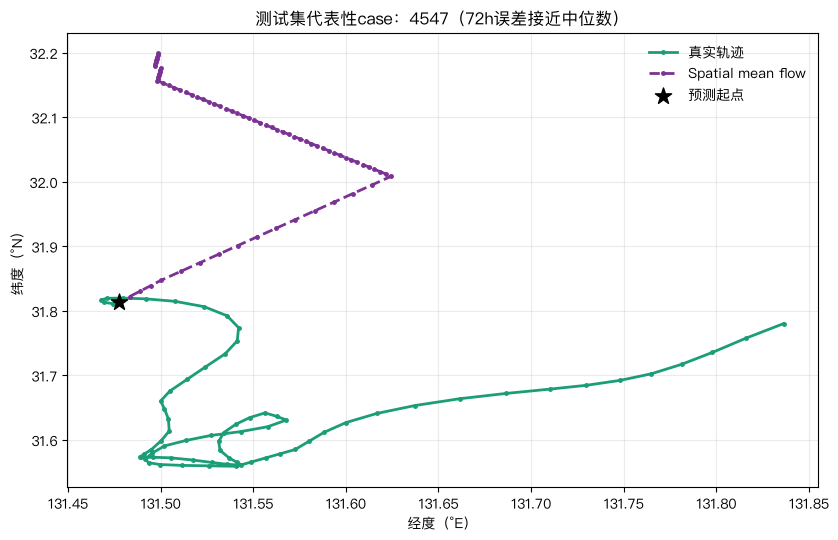

In [11]:
median_final = test_case_metrics['final_72h_error_km'].median()
example_id = test_case_metrics.loc[
    (test_case_metrics['final_72h_error_km'] - median_final).abs().idxmin(),
    'forecast_case_id',
]
example = test_eval[test_eval['forecast_case_id'].eq(example_id)].sort_values('lead_time_hours')

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.plot(
    example['true_longitude'], example['true_latitude'], '-o', markersize=2.5,
    linewidth=2, color='#1b9e77', label='真实轨迹',
)
ax.plot(
    example['pred_longitude'], example['pred_latitude'], '--o', markersize=2.5,
    linewidth=2, color='#7b3294', label='Spatial mean flow',
)
ax.scatter(
    example['origin_longitude'].iloc[0], example['origin_latitude'].iloc[0],
    marker='*', s=150, color='black', label='预测起点', zorder=5,
)
ax.set(
    xlabel='经度（°E）', ylabel='纬度（°N）',
    title=f'测试集代表性case：{int(example_id)}（72h误差接近中位数）',
)
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'spatial_mean_flow_example_trajectory.png', dpi=200, bbox_inches='tight')
plt.show()

## 10. 保存可复现结果

保存流场网格、小型汇总文件和poster可用图片。完整逐小时预测可以通过本notebook重新生成，因此不额外上传大型预测表。

In [12]:
fine_flow.to_csv(OUTPUT_DIR / 'spatial_mean_flow_grid.csv', index=False)
lead_metrics.to_csv(OUTPUT_DIR / 'spatial_mean_flow_lead_metrics.csv', index=False)
test_case_metrics.to_csv(OUTPUT_DIR / 'spatial_mean_flow_test_case_metrics.csv', index=False)
fallback_usage.to_csv(OUTPUT_DIR / 'spatial_mean_flow_fallback_usage.csv', index=False)
summary.to_csv(OUTPUT_DIR / 'spatial_mean_flow_summary.csv', index=False)

saved_files = sorted(p.name for p in OUTPUT_DIR.glob('spatial_mean_flow_*'))
print('已保存：')
for name in saved_files:
    print(' -', name)

已保存：
 - spatial_mean_flow_error_curve.png
 - spatial_mean_flow_example_trajectory.png
 - spatial_mean_flow_fallback_usage.csv
 - spatial_mean_flow_field.png
 - spatial_mean_flow_grid.csv
 - spatial_mean_flow_lead_metrics.csv
 - spatial_mean_flow_summary.csv
 - spatial_mean_flow_test_case_metrics.csv
